<div style="background-color: #f5f5f5; padding: 20px; border-radius: 10px; border: 1px solid #e0e0e0;">
<table style="width:100%; border:none;">
  <tbody><tr style="border:none;">
    <td style="width:20%; text-align:center; border:none; vertical-align:middle;">
      <img src="https://i.ibb.co/pjbk15cs/UI-Logo.png" alt="UI Logo" width="100">
    </td>
    <td style="width:60%; text-align:center; border:none; vertical-align:middle;">
      <h1 style="margin:0; color:#333;">University of Isfahan</h1>
      <h2 style="margin:0; color:#555; font-weight:normal;">Faculty of Mathematics and Statistics</h2>
      <hr style="border: 1px solid #ccc; margin-top:15px; margin-bottom:15px;">
      <h3 style="margin:0; color:#0056b3;">First Practical Homework: Linear Regression</h3>
    </td>
    <td style="width:20%; text-align:center; border:none; vertical-align:middle;">
      <img src="https://i.ibb.co/pjbk15cs/UI-Logo.png" alt="UI Logo" width="100">
    </td>
  </tr>
</tbody></table>
</div>

<div style="font-size: 1.1em; margin-top: 25px; margin-bottom: 25px;">
<table style="width: 60%; margin-left: auto; margin-right: auto; border: none;">
    <tbody><tr>
        <td style="text-align: right; padding: 8px; width: 35%;"><strong>Course:</strong></td>
        <td style="text-align: left; padding: 8px;">Machine Learning</td>
    </tr>
    <tr>
        <td style="text-align: right; padding: 8px;"><strong>Instructor:</strong></td>
        <td style="text-align: left; padding: 8px;">Dr. Mohsen Alambardar</td>
    </tr>
    <tr>
        <td style="text-align: right; padding: 8px;"><strong>Semester:</strong></td>
        <td style="text-align: left; padding: 8px;">Fall 1404-1405</td>
    </tr>
    <tr>
        <td style="text-align: right; padding: 8px;"><strong>Student Name:</strong></td>
        <td style="text-align: left; padding: 8px;"><em>Hosna Soltanolkottabi</em></td>
    </tr>
    <tr>
        <td style="text-align: right; padding: 8px;"><strong>Student ID:</strong></td>
        <td style="text-align: left; padding: 8px;"><em></em></td>
    </tr>
</tbody></table>
</div>

## **HW1-P: The Effect of the Learning Rate in Gradient Descent**

This notebook will guide you through a hands-on exercise to visualize why choosing a proper **learning rate ($\alpha$)** is crucial for the gradient descent algorithm. Answer the sections with **Your Task** in their title.

**Our goal:** We will implement batch gradient descent and run it on a simple dataset using three different learning rates to observe the outcomes:
1.  A "good" learning rate that converges efficiently.
2.  A learning rate that is too small, leading to slow convergence.
3.  A learning rate that is too large, causing the algorithm to diverge.

### **1. Setup: Importing Libraries and Preparing the Data**

First, we'll import the necessary libraries (`numpy` for numerical operations and `matplotlib` for plotting) and create our dataset. The dataset is simple: `X` represents the size of a house, and `y` represents its price. We will also add the intercept term (a column of ones) to our `X` matrix, which we'll call `X_b`.

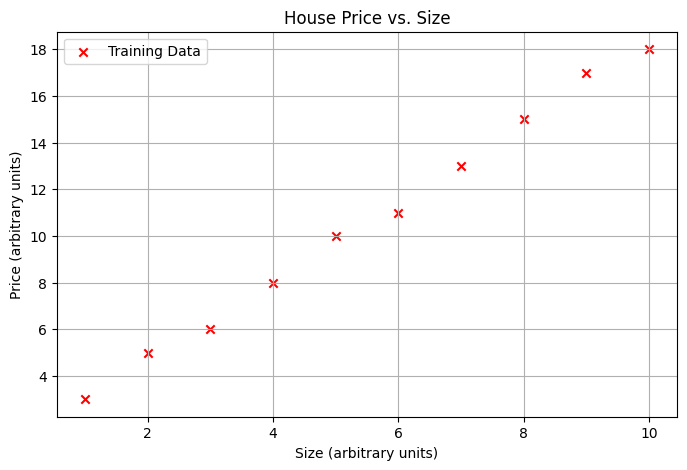

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# --- The Dataset ---
# A simple dataset of house size (X) vs. price (y)
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
y = np.array([3, 5, 6, 8, 10, 11, 13, 15, 17, 18])
m = len(y) # Number of training examples

# Add a column of ones to X for the intercept term theta_0
# This changes X from a shape of (10,) to X_b of shape (10, 2)
X_b = np.c_[np.ones((m, 1)), X]

# --- Let's visualize the data ---
plt.figure(figsize=(8, 5))
plt.scatter(X, y, marker='x', color='red', label='Training Data')
plt.title('House Price vs. Size')
plt.xlabel('Size (arbitrary units)')
plt.ylabel('Price (arbitrary units)')
plt.legend()
plt.grid(True)
plt.show()

### **2. Defining the Cost Function**

The **cost function** measures how well our model's predictions match the actual data. For linear regression, we use the **Mean Squared Error (MSE)**, defined as:

$$ J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} (h_\theta(x^{(i)}) - y^{(i)})^2 $$

Our goal in gradient descent is to find the values of $\theta$ that minimize this function. The code below implements this formula.

In [8]:
def compute_cost(X_b, y, theta):
    """
    Computes the cost for linear regression (Mean Squared Error).

    Args:
        X_b (ndarray): The input features with a column of ones. Shape (m, n+1).
        y (ndarray): The target values. Shape (m,).
        theta (ndarray): The parameters of the model. Shape (n+1,).

    Returns:
        float: The computed cost.
    """
    m = len(y)
    predictions = X_b.dot(theta)
    errors = predictions - y
    sqr_errors = errors ** 2
    cost = 1 / (2 * m) * np.sum(sqr_errors)
    return cost

### **3. Your Task: Implement the Gradient Descent Algorithm**

Now for the main part of the exercise. You need to implement the gradient descent algorithm. The update rule for the parameters in each iteration is:

$$ \theta_j := \theta_j - \alpha \frac{1}{m} \sum_{i=1}^{m} (h_\theta(x^{(i)}) - y^{(i)}) x_j^{(i)} $$

In our vectorized implementation, we'll calculate the gradients for all $\theta_j$ at once and update `theta` simultaneously. **Fill in the missing code below.**

In [9]:
def gradient_descent(X_b, y, theta, alpha, iterations):
    """
    Performs gradient descent to learn theta.

    Args:
        X_b (ndarray): Input features with a column of ones.
        y (ndarray): Target values.
        theta (ndarray): Initial parameters.
        alpha (float): The learning rate.
        iterations (int): The number of iterations to run.

    Returns:
        tuple: A tuple containing the final theta values and the history of cost values.
    """
    m = len(y)
    cost_history = np.zeros(iterations)

    for i in range(iterations):
        # --- YOUR CODE HERE ---
        # This can be done in 3 lines:
        # 1. Calculate predictions: h(x) = X_b * theta
        predictions = X_b @ theta
        # 2. Calculate the errors: predictions - y
        errors = predictions - y
        # 3. Calculate the gradients and update theta
        gradients = 1/m * X_b.T @ errors
        theta = theta - alpha * gradients
        #    Hint: For an efficient solution, calculate the gradients for all theta 
        #          parameters at once using matrix operations (vectorization).
        # ----------------------

        cost_history[i] = compute_cost(X_b, y, theta)

    return theta, cost_history

### **4. Running the Experiment with Different Learning Rates**

Now we'll run our `gradient_descent` function three times, each with a different learning rate, to observe how `alpha` affects convergence.

In [10]:
# --- Experiment Setup ---
iterations = 100
initial_theta = np.zeros(2) # Start with theta_0 = 0 and theta_1 = 0

# --- Case 1: A "good" learning rate ---
alpha_good = 0.01
theta_good, cost_history_good = gradient_descent(X_b, y, initial_theta, alpha_good, iterations)

# --- Case 2: A learning rate that is too small ---
alpha_small = 0.0001
theta_small, cost_history_small = gradient_descent(X_b, y, initial_theta, alpha_small, iterations)

# --- Case 3: A learning rate that is too large ---
alpha_large = 0.09
theta_large, cost_history_large = gradient_descent(X_b, y, initial_theta, alpha_large, iterations)

print(f"Final theta for alpha={alpha_good}: {theta_good}")
print(f"Final theta for alpha={alpha_small}: {theta_small}")
print(f"Final theta for alpha={alpha_large}: {theta_large}")

Final theta for alpha=0.01: [0.45443195 1.81363954]
Final theta for alpha=0.0001: [0.08815548 0.59878516]
Final theta for alpha=0.09: [-6.90219961e+39 -4.80518876e+40]


### **5. Visualizing the Convergence**

The best way to understand the results is to plot the cost function, $J(\theta)$, over the number of iterations for each learning rate. The plots below shows how the "error" of our model changes with each step of gradient descent.

To properly visualize both outcomes, we will create two plots side-by-side.
* **The left plot** will focus only on the learning rates that converge, with a defined y-axis to see their behavior clearly.
* **The right plot** will show the learning rate that diverges, allowing its y-axis to scale automatically to show the explosion in cost.

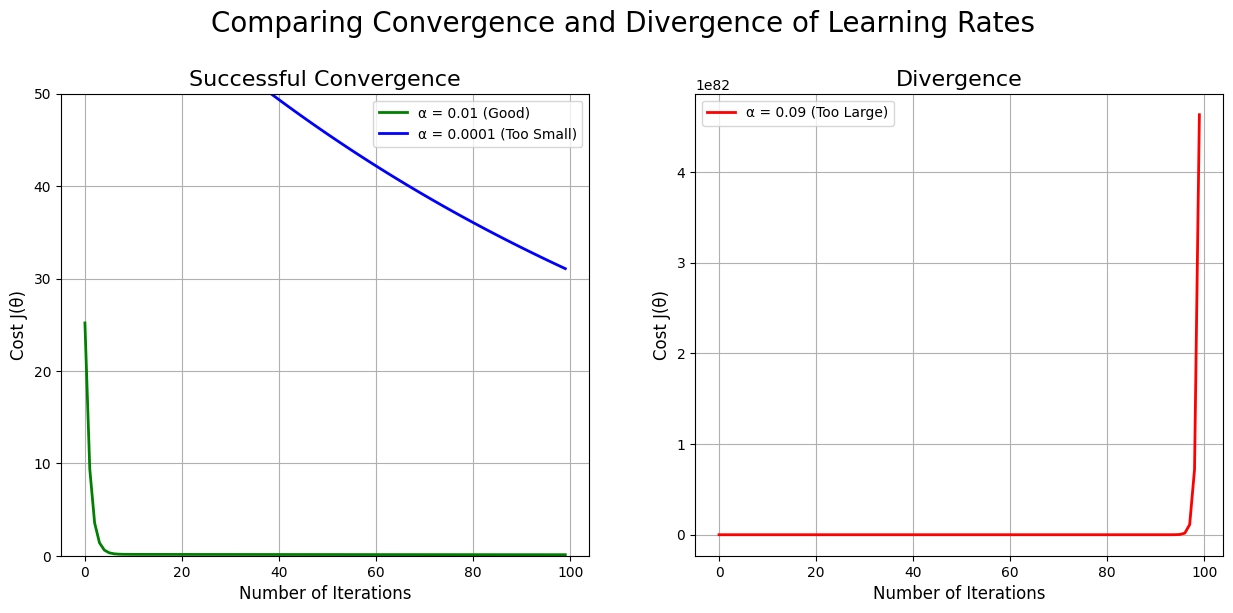

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# --- Plot 1: Convergence ---
ax1.plot(range(iterations), cost_history_good, label=f'α = {alpha_good} (Good)', color='green', linewidth=2)
ax1.plot(range(iterations), cost_history_small, label=f'α = {alpha_small} (Too Small)', color='blue', linewidth=2)
ax1.set_title('Successful Convergence', fontsize=16)
ax1.set_xlabel('Number of Iterations', fontsize=12)
ax1.set_ylabel('Cost J(θ)', fontsize=12)
ax1.set_ylim(0, 50) # Set a y-limit to see the details
ax1.legend()
ax1.grid(True)

# --- Plot 2: Divergence ---
ax2.plot(range(iterations), cost_history_large, label=f'α = {alpha_large} (Too Large)', color='red', linewidth=2)
ax2.set_title('Divergence', fontsize=16)
ax2.set_xlabel('Number of Iterations', fontsize=12)
ax2.set_ylabel('Cost J(θ)', fontsize=12)
# No y-limit here, so it can scale to the cost values
ax2.legend()
ax2.grid(True)

fig.suptitle('Comparing Convergence and Divergence of Learning Rates', fontsize=20, y=1.02)
plt.show()

### **6. Your Task: Analysis of Different Choices for Alpha**

Carefully observe the plot you generated and answer the following questions:

1.  **For $\alpha = 0.01$ (Good Rate):** Describe the shape of the green curve. Does the cost decrease quickly and then stabilize? What does this tell you about the convergence of the algorithm?

بله، هزینه به سرعت کاهش پیدا کرده و سپس برابر مقدار ثابت صفر میشود. چون به مقدار صفر رسیدیم یعنی فرضیه پیدا شده کاملا مطابق با نمونه‌های آموزشی است و به همگرایی رسیدیم.(نقطه بهینه سراسری پیدا شده)

2.  **For $\alpha = 0.0001$ (Too Small):** Look at the blue curve. How does its rate of decrease compare to the green curve? If you were to run it for many more iterations, do you think it would eventually reach the same minimum cost as the green curve? What is the main disadvantage of using such a small learning rate?

سرعت کاهش هزینه(سرعت همگرایی) در این حالت کند است. ولی در نهایت در تکرارهای بسیار بالا جواب بهینه سراسری حاصل خواهد شد که برابر با جواب بهینه سراسری در حالتی است که آلفا برابر 0.01 است. مشکل اصلی این نرخ یادگیری پایین این است که تعداد تکرارها برای رسیدن به بهینه سراسری زیاد است و هنگامی که تعداد داده‌های آموزشی و ویژگی‌های ما زیاد است این فرایند رسیدن به همگرایی بسیار زمان‌بر میشود.

3.  **For $\alpha = 0.05$ (Too Large):** Examine the red curve. What is happening to the cost with each iteration? This phenomenon is called **divergence**. Based on the gradient descent update rule, explain why a large `alpha` can cause the cost to increase instead of decrease.

همانطور که مشاهده میشود مقدار هزینه به جای کم شدن بعد از هر تکرار رفته رفته زیاد میشود در واقع هنگامی که نرخ یادگیری بیش از حد بزرگ باشد باعث میشود ما گام حرکت بزرگی داشته باشیم در حدی که از روی نقطه بهینه پرش میکنیم و در نتیجه ممکن است نقطه بعدی که در آن قرار میگیریم گرادیان بزرگتری نسبت به نقطه پیشین داشته باشد در نتیجه در هر تکرار مقدار آلفا ضرب در گرادیان بزرگ و بزرگتر میشود و واگرایی اتفاق می‌افتد.